# Практична робота №1
## Лінійна регресія, оптимізація та статистичний аналіз

Студент: Панчишин Володимир

**Мета:** Реалізувати лінійну регресію й три варіанти градієнтного спуску, перевірити якість прогнозу та припущення моделі.

Джерело завдання: https://github.com/olehsinkevych/machine-learning

**Відтворення:** середовище Python 3.12, залежності в requirements.txt; перед запуском усієї роботи завантажте дані командою `python download_data.py`. Усі результати нижче отримуються виконанням коду, а не копіюванням готових таблиць.

In [1]:
from pathlib import Path
import sys, os
for name in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ.setdefault(name, '2')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'project' / 'common.py').is_file())
sys.path.insert(0, str(ROOT / 'project'))
import common
from IPython.display import display, Image
import pandas as pd
import json

## 1. Теоретичні пояснення та відповіді на питання

### Як улаштована модель
Прогноз лінійної регресії: ŷ = Xw + b. Оптимізую J = ||Xw + b - y||² / (2m). Градієнти дорівнюють Xᵀ(ŷ-y)/m і середньому залишку. Обчислення векторизовані; цикл проходить лише по епохах і батчах.

### Три оптимізатори
Batch GD використовує всю навчальну вибірку на крок, SGD - один приклад, mini-batch - 64 приклади. Число кроків за епоху різне, тому швидкість за епохами не тотожна швидкості за часом. Швидкість навчання вибрана за Validation, а не Test.

### Чому поділ передує перетворенням
Параметри імпутації, стандартизації, one-hot словника та відбору ознак визначено лише на Train. Інакше тестова інформація потрапила б у навчання - це data leakage. Невідомі категорії на Validation/Test дають нульовий блок через handle_unknown="ignore".

### Зміст R²
R² = 1 - SSE/SST порівнює модель із прогнозом середнього цільової змінної оцінюваної вибірки. Значення може бути від’ємним, якщо модель гірша за цю константу. Добре Train R² разом із помітно гіршим Test R² може свідчити про перенавчання або зміну розподілу.

### Діагностика і Ridge
Нормальність і гомоскедастичність важливі для класичних довірчих інтервалів, проте не є умовами існування прогнозу. Великий VIF означає нестійкість окремих коефіцієнтів, а не автоматично поганий прогноз. Для Ridge додаю λ||w||²/2; новий градієнт за w містить λw. Bias не штрафую. Діагностичні допоміжні регресії не замінюють основне навчання градієнтним спуском.

### Кодування та масштаб штрафу
Номінальні категорії закодував One-Hot: Ordinal нав’язав би довільний порядок, а Target Encoding вимагав би окремого out-of-fold контролю витоку. У Ridge використано еквівалентну параметризацію J = MSE/2 + λ_code||w||²/2. Для форми методички λ_method||w||²/(2m) маємо λ_code = λ_method/m; це зміна позначення коефіцієнта, а не інший вид штрафу.

## 2. Повна реалізація

Далі міститься власна реалізація обчислень цієї роботи. Код також винесено в окремий файл `project/lab01.py`.

In [2]:
"""Практична 1: лінійна регресія на Ames, три власні оптимізатори NumPy."""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score
from common import DATA, folder, savefig, dump, numerical_gradient

In [3]:
class LinearGD:
    def __init__(self, lr=0.01, batch=None, epochs=500, ridge=0.0, seed=42):
        self.lr, self.batch, self.epochs, self.ridge, self.seed = (
            lr,
            batch,
            epochs,
            ridge,
            seed,
        )

    def predict(self, x):
        return x @ self.w + self.b

    def loss_grad(self, x, y):
        err = self.predict(x) - y
        n = len(y)
        return (
            0.5 * np.mean(err**2) + 0.5 * self.ridge * np.dot(self.w, self.w),
            x.T @ err / n + self.ridge * self.w,
            np.mean(err),
        )

    def fit(self, x, y, xv, yv):
        rng = np.random.default_rng(self.seed)
        self.w = np.zeros(x.shape[1])
        self.b = np.zeros(1)
        best = np.inf
        stale = 0
        self.history = []
        for epoch in range(self.epochs):
            ids = np.arange(len(y)) if self.batch is None else rng.permutation(len(y))
            size = self.batch or len(y)
            for start in range(0, len(y), size):
                batch = ids[start : start + size]
                loss, g, gb = self.loss_grad(x[batch], y[batch])
                self.w -= self.lr * g
                self.b -= self.lr * gb
            train_loss = float(self.loss_grad(x, y)[0])
            val_loss = float(0.5 * np.mean((self.predict(xv) - yv) ** 2))
            self.history.append([epoch + 1, train_loss, val_loss])
            if not np.isfinite(train_loss) or train_loss > 1e12:
                break
            if val_loss < best - 1e-7:
                best = val_loss
                weights = self.w.copy(), self.b.copy()
                stale = 0
            else:
                stale += 1
            if stale >= 80:
                break
        if np.isfinite(best):
            self.w, self.b = weights
        return self

In [4]:
def metrics(y, p):
    ssr = np.sum((y - p) ** 2)
    sst = np.sum((y - y.mean()) ** 2)
    r = 1 - ssr / sst
    assert np.isclose(r, r2_score(y, p))
    return {
        "r2": float(r),
        "rmse": float(np.sqrt(np.mean((y - p) ** 2))),
        "mae": float(np.mean(abs(y - p))),
    }

In [5]:
def run():
    out = folder(1)
    df = pd.read_csv(DATA / "ames_housing.txt", sep="\t")
    ids = np.arange(len(df))
    tr, hold = train_test_split(ids, test_size=0.4, random_state=42)
    va, te = train_test_split(hold, test_size=0.5, random_state=42)
    # Відбір ознак та всі статистики перетворень визначаються лише на Train.
    candidates = [
        "Overall Qual",
        "Gr Liv Area",
        "Garage Cars",
        "Garage Area",
        "Total Bsmt SF",
        "1st Flr SF",
        "Year Built",
        "Full Bath",
        "Year Remod/Add",
        "TotRms AbvGrd",
        "Lot Area",
        "Fireplaces",
        "Mas Vnr Area",
        "BsmtFin SF 1",
    ]
    corr = (
        df.iloc[tr][candidates + ["SalePrice"]]
        .corr()["SalePrice"]
        .drop("SalePrice")
        .sort_values(key=abs, ascending=False)
    )
    numeric = list(corr.index[:10])
    categorical = ["Neighborhood", "Bldg Type", "House Style", "Kitchen Qual"]
    prep = ColumnTransformer(
        [
            (
                "num",
                make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
                numeric,
            ),
            (
                "cat",
                make_pipeline(
                    SimpleImputer(strategy="most_frequent"),
                    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                ),
                categorical,
            ),
        ]
    )
    x = prep.fit_transform(df.iloc[tr])
    xv = prep.transform(df.iloc[va])
    xt = prep.transform(df.iloc[te])
    y = df.SalePrice.to_numpy(float)
    ym = y[tr].mean()
    ys = y[tr].std()
    yt = (y[tr] - ym) / ys
    yv = (y[va] - ym) / ys
    model = LinearGD()
    model.w = np.zeros(x.shape[1])
    model.b = np.zeros(1)
    _, g, gb = model.loss_grad(x[:15], yt[:15])
    grad = numerical_gradient(
        lambda: model.loss_grad(x[:15], yt[:15])[0],
        [model.w, model.b],
        [g, np.array([gb])],
    )
    trials = []
    selected = {}
    results = {}
    histories = {}
    for name, batch, epochs, rates in [
        ("Batch GD", None, 2200, [0.01, 0.03, 0.08]),
        ("SGD", 1, 220, [0.0005, 0.002, 0.008]),
        ("Mini-batch GD", 64, 650, [0.003, 0.01, 0.03]),
    ]:
        options = []
        for lr in rates:
            m = LinearGD(lr, batch, epochs).fit(x, yt, xv, yv)
            score = metrics(y[va], m.predict(xv) * ys + ym)
            trials.append({"method": name, "lr": lr, "epochs": len(m.history), **score})
            options.append((score["rmse"], m))
        m = min(options, key=lambda z: z[0])[1]
        selected[name] = m
        results[name] = {
            "learning_rate": m.lr,
            "batch_size": batch or len(tr),
            "epochs": len(m.history),
            "train": metrics(y[tr], m.predict(x) * ys + ym),
            "validation": metrics(y[va], m.predict(xv) * ys + ym),
            "test": metrics(y[te], m.predict(xt) * ys + ym),
        }
        histories[name] = m.history
        h = np.asarray(m.history)
        plt.plot(h[:, 0], h[:, 1], label=name)
    plt.xlabel("Епоха")
    plt.ylabel("J = MSE / 2, стандартизована ціна")
    plt.legend()
    savefig(out, "optimization")
    winner = min(selected, key=lambda n: results[n]["validation"]["rmse"])
    m = selected[winner]
    pred = m.predict(x) * ys + ym
    res = y[tr] - pred
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes[0, 0].scatter(pred, res, s=8, alpha=0.4)
    axes[0, 0].axhline(0, color="black", lw=1)
    axes[0, 0].set(xlabel="Прогнозована ціна, USD", ylabel="Залишок, USD")
    stats.probplot(res, plot=axes[0, 1])
    axes[0, 1].set(
        title="Q-Q залишків",
        xlabel="Теоретичний квантиль",
        ylabel="Упорядкований залишок",
    )
    stdres = (res - res.mean()) / res.std()
    axes[1, 0].scatter(pred, np.sqrt(abs(stdres)), s=8, alpha=0.4)
    axes[1, 0].set(
        xlabel="Прогнозована ціна, USD", ylabel="√|стандартизований залишок|"
    )
    axes[1, 1].hist(res, bins=35, color="#28649b")
    axes[1, 1].set(xlabel="Залишок, USD", ylabel="Кількість")
    savefig(out, "diagnostics")
    c = df.iloc[tr][numeric + ["SalePrice"]].corr()
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(c, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.grid(False)
    ax.set(
        xticks=range(len(c)),
        yticks=range(len(c)),
        xticklabels=c.columns,
        yticklabels=c.columns,
    )
    plt.setp(ax.get_xticklabels(), rotation=65, ha="right")
    fig.colorbar(im, ax=ax)
    savefig(out, "correlations")
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].hist(y[tr], bins=35)
    axes[0].set(xlabel="SalePrice, USD", ylabel="Кількість")
    axes[1].scatter(df.iloc[tr]["Gr Liv Area"], y[tr], s=8, alpha=0.4)
    axes[1].set(xlabel="Житлова площа, ft²", ylabel="SalePrice, USD")
    savefig(out, "eda")
    shapiro = stats.shapiro(res)
    # VIF і Breusch-Pagan є діагностичними допоміжними регресіями, не способом навчання основної моделі.
    xn = prep.named_transformers_["num"].transform(df.iloc[tr][numeric])
    vifs = {}
    for j, name in enumerate(numeric):
        other = np.column_stack([np.ones(len(xn)), np.delete(xn, j, axis=1)])
        coef = np.linalg.lstsq(other, xn[:, j], rcond=None)[0]
        r = metrics(xn[:, j], other @ coef)["r2"]
        vifs[name] = 1 / (1 - r)
    z = np.column_stack([np.ones(len(x)), x])
    res2 = res**2
    coef = np.linalg.lstsq(z, res2, rcond=None)[0]
    bp = len(res) * metrics(res2, z @ coef)["r2"]
    bp_df = np.linalg.matrix_rank(z) - 1
    # Додатковий обов'язковий експеримент: NumPy Ridge, λ обрано на Validation.
    ridge = []
    for strength in [0.001, 0.01, 0.1, 1.0]:
        rm = LinearGD(0.03, 64, 650, ridge=strength).fit(x, yt, xv, yv)
        ridge.append((metrics(y[va], rm.predict(xv) * ys + ym)["rmse"], strength, rm))
    _, strength, rm = min(ridge, key=lambda z: z[0])
    fig, ax = plt.subplots()
    order = np.argsort(abs(m.w))[-15:]
    ax.barh(np.arange(15) - 0.18, m.w[order], height=0.35, label=winner)
    ax.barh(np.arange(15) + 0.18, rm.w[order], height=0.35, label="Ridge")
    ax.set_yticks(range(15), prep.get_feature_names_out()[order])
    ax.set_xlabel("Вага для стандартизованої цілі")
    ax.legend()
    savefig(out, "ridge_weights")
    data = {
        "source": "Ames Housing, De Cock (2011), 2930 спостережень",
        "shape": list(df.shape),
        "split": {"train": len(tr), "validation": len(va), "test": len(te)},
        "numeric": numeric,
        "categorical": categorical,
        "correlations": corr.to_dict(),
        "missing_train": df.iloc[tr][numeric + categorical].isna().sum().to_dict(),
        "encoded_features": x.shape[1],
        "models": results,
        "trials": trials,
        "winner": winner,
        "gradient_check": grad,
        "shapiro": {"statistic": float(shapiro.statistic), "p": float(shapiro.pvalue)},
        "breusch_pagan": {
            "statistic": bp,
            "df": int(bp_df),
            "p": float(stats.chi2.sf(bp, bp_df)),
        },
        "vif": vifs,
        "ridge": {
            "lambda": strength,
            "norm_unregularized": float(np.linalg.norm(m.w)),
            "norm_regularized": float(np.linalg.norm(rm.w)),
            "validation": metrics(y[va], rm.predict(xv) * ys + ym),
            "test": metrics(y[te], rm.predict(xt) * ys + ym),
        },
    }
    np.savez(out / "split_indices.npz", train=tr, validation=va, test=te)
    pd.DataFrame(
        {"actual": y[te], "prediction": m.predict(xt) * ys + ym, "row": te}
    ).to_csv(out / "test_predictions.csv", index=False)
    import joblib

    joblib.dump(prep, out / "preprocessor.joblib")
    np.savez(out / "model_weights.npz", w=m.w, b=m.b, target_mean=ym, target_std=ys)
    dump(out, data)
    print("LAB 1 COMPLETE", winner, results[winner]["test"], flush=True)
    return data

In [6]:
run()

LAB 1 COMPLETE SGD {'r2': 0.8630497348138302, 'rmse': 30555.014055573978, 'mae': 19261.074648278453}


{'source': 'Ames Housing, De Cock (2011), 2930 спостережень',
 'shape': [2930, 82],
 'split': {'train': 1758, 'validation': 586, 'test': 586},
 'numeric': ['Overall Qual',
  'Gr Liv Area',
  'Garage Cars',
  'Total Bsmt SF',
  'Garage Area',
  '1st Flr SF',
  'Year Built',
  'Full Bath',
  'Mas Vnr Area',
  'Year Remod/Add'],
 'categorical': ['Neighborhood', 'Bldg Type', 'House Style', 'Kitchen Qual'],
 'correlations': {'Overall Qual': 0.7912382665071479,
  'Gr Liv Area': 0.7038955980866689,
  'Garage Cars': 0.6424014247042827,
  'Total Bsmt SF': 0.6421257239418854,
  'Garage Area': 0.6306204348269888,
  '1st Flr SF': 0.6239463344262846,
  'Year Built': 0.5432920181648935,
  'Full Bath': 0.5427913828802416,
  'Mas Vnr Area': 0.5124403080345359,
  'Year Remod/Add': 0.5110514544583687,
  'TotRms AbvGrd': 0.4899073500112944,
  'Fireplaces': 0.4700915008385448,
  'BsmtFin SF 1': 0.4296739740905747,
  'Lot Area': 0.2683028574643475},
 'missing_train': {'Overall Qual': 0,
  'Gr Liv Area': 0,

In [7]:
result_path = ROOT / 'lab_01' / 'results' / 'results.json'
R = json.loads(result_path.read_text(encoding='utf-8'))
from result_tables import tables, conclusions

## 3. Результати та їх інтерпретація

### Таблиця 1. Розміри незалежних вибірок

У таблиці 1 наведено розміри незалежних вибірок. Статистики перетворень визначено лише на тренувальній частині. Валідаційні та тестові індекси збережено окремо.

In [8]:
entry = tables(1, R)[0]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Вибірка,Спостережень
0,train,1758
1,validation,586
2,test,586


### Таблиця 2. Оцінки трьох оптимізаторів

У таблиці 2 наведено оцінки трьох оптимізаторів. Метод вибрано за Validation RMSE до оцінювання Test. Значення R² обчислено власною формулою та звірено зі scikit-learn.

In [9]:
entry = tables(1, R)[1]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Метод,Train R²,Val R²,Test R²,"Test RMSE, USD"
0,Batch GD,"0,8659","0,8068","0,8732","29397,92"
1,SGD,"0,8645","0,8193","0,8630","30555,01"
2,Mini-batch GD,"0,8647","0,8152","0,8665","30164,08"


### Таблиця 3. Налаштування оптимізації

У таблиці 3 наведено налаштування оптимізації. Для кожного методу перевірено три швидкості навчання; збережено кращу за Validation модель. Після 80 епох без поліпшення спрацьовує рання зупинка.

In [10]:
entry = tables(1, R)[2]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Метод,α,Batch,Епох
0,Batch GD,"0,0800",1758,2200
1,SGD,"0,0020",1,220
2,Mini-batch GD,"0,0300",64,447


### Таблиця 4. Діагностика залишків і залежності ознак

У таблиці 4 наведено діагностика залишків і залежності ознак. Малі p-значення вказують на порушення відповідних нульових гіпотез. Це обмежує класичну інтерпретацію коефіцієнтів, але не скасовує фактичну оцінку прогнозу на відкладених даних.

In [11]:
entry = tables(1, R)[3]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Перевірка,Значення
0,Shapiro-Wilk p,"4,42e-38"
1,Breusch-Pagan p,"1,37e-66"
2,Найбільший VIF,"5,63"
3,Чисельна похибка градієнта,"5,54e-11"


### Таблиця 5. Додатковий експеримент Ridge

У таблиці 5 наведено додатковий експеримент Ridge. Коефіцієнт λ=0,0010 вибрано за Validation. Порівняння не припускає, що штраф обов’язково підвищить точність.

In [12]:
entry = tables(1, R)[4]
display(pd.DataFrame(entry[2], columns=entry[1]))

,Показник,Без штрафу,Ridge
0,Норма ваг,"1,7097","1,4322"
1,"Test RMSE, USD","30555,01","30071,03"
2,Test R²,"0,8630","0,8674"


## 4. Графіки

### Рисунок 1. Розподіл цін та зв’язок із житловою площею

На рисунку 1 зображено розподіл цін та зв’язок із житловою площею. Розподіл SalePrice має правий хвіст. Зв’язок із площею не зводиться до однієї точної прямої; помітні окремі великі будинки з нетиповими цінами.

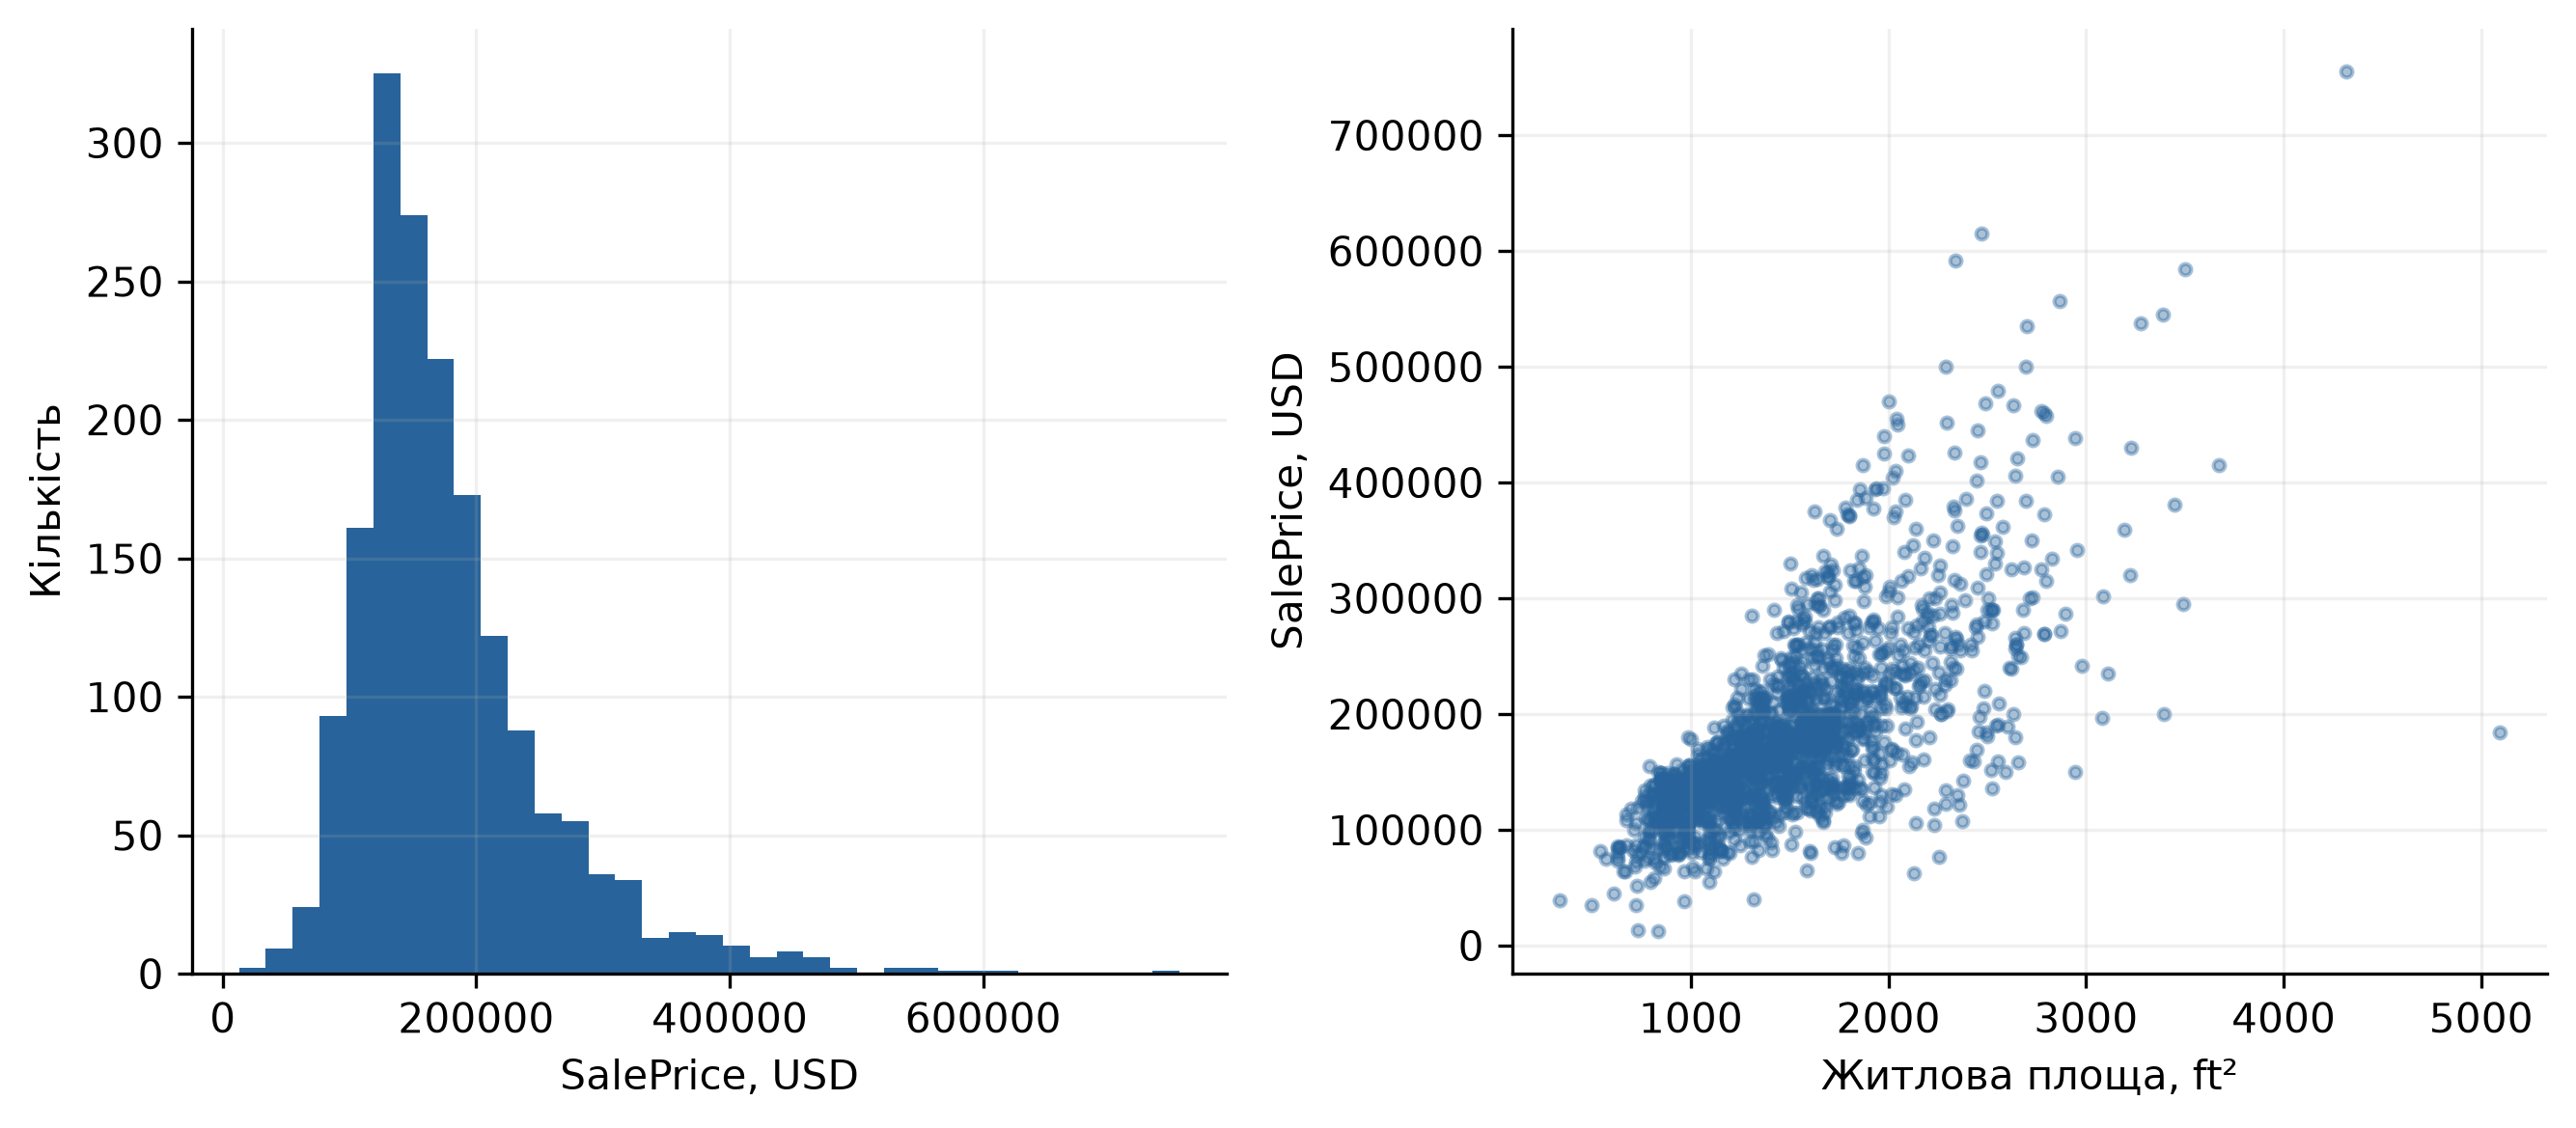

In [13]:
display(Image(filename=str(ROOT / 'lab_01' / 'results' / 'eda.png')))

### Рисунок 2. Кореляції відібраних числових ознак на Train

На рисунку 2 зображено кореляції відібраних числових ознак на Train. Кореляції використано для первинного відбору, а парні залежності ознак - для діагностики мультиколінеарності.

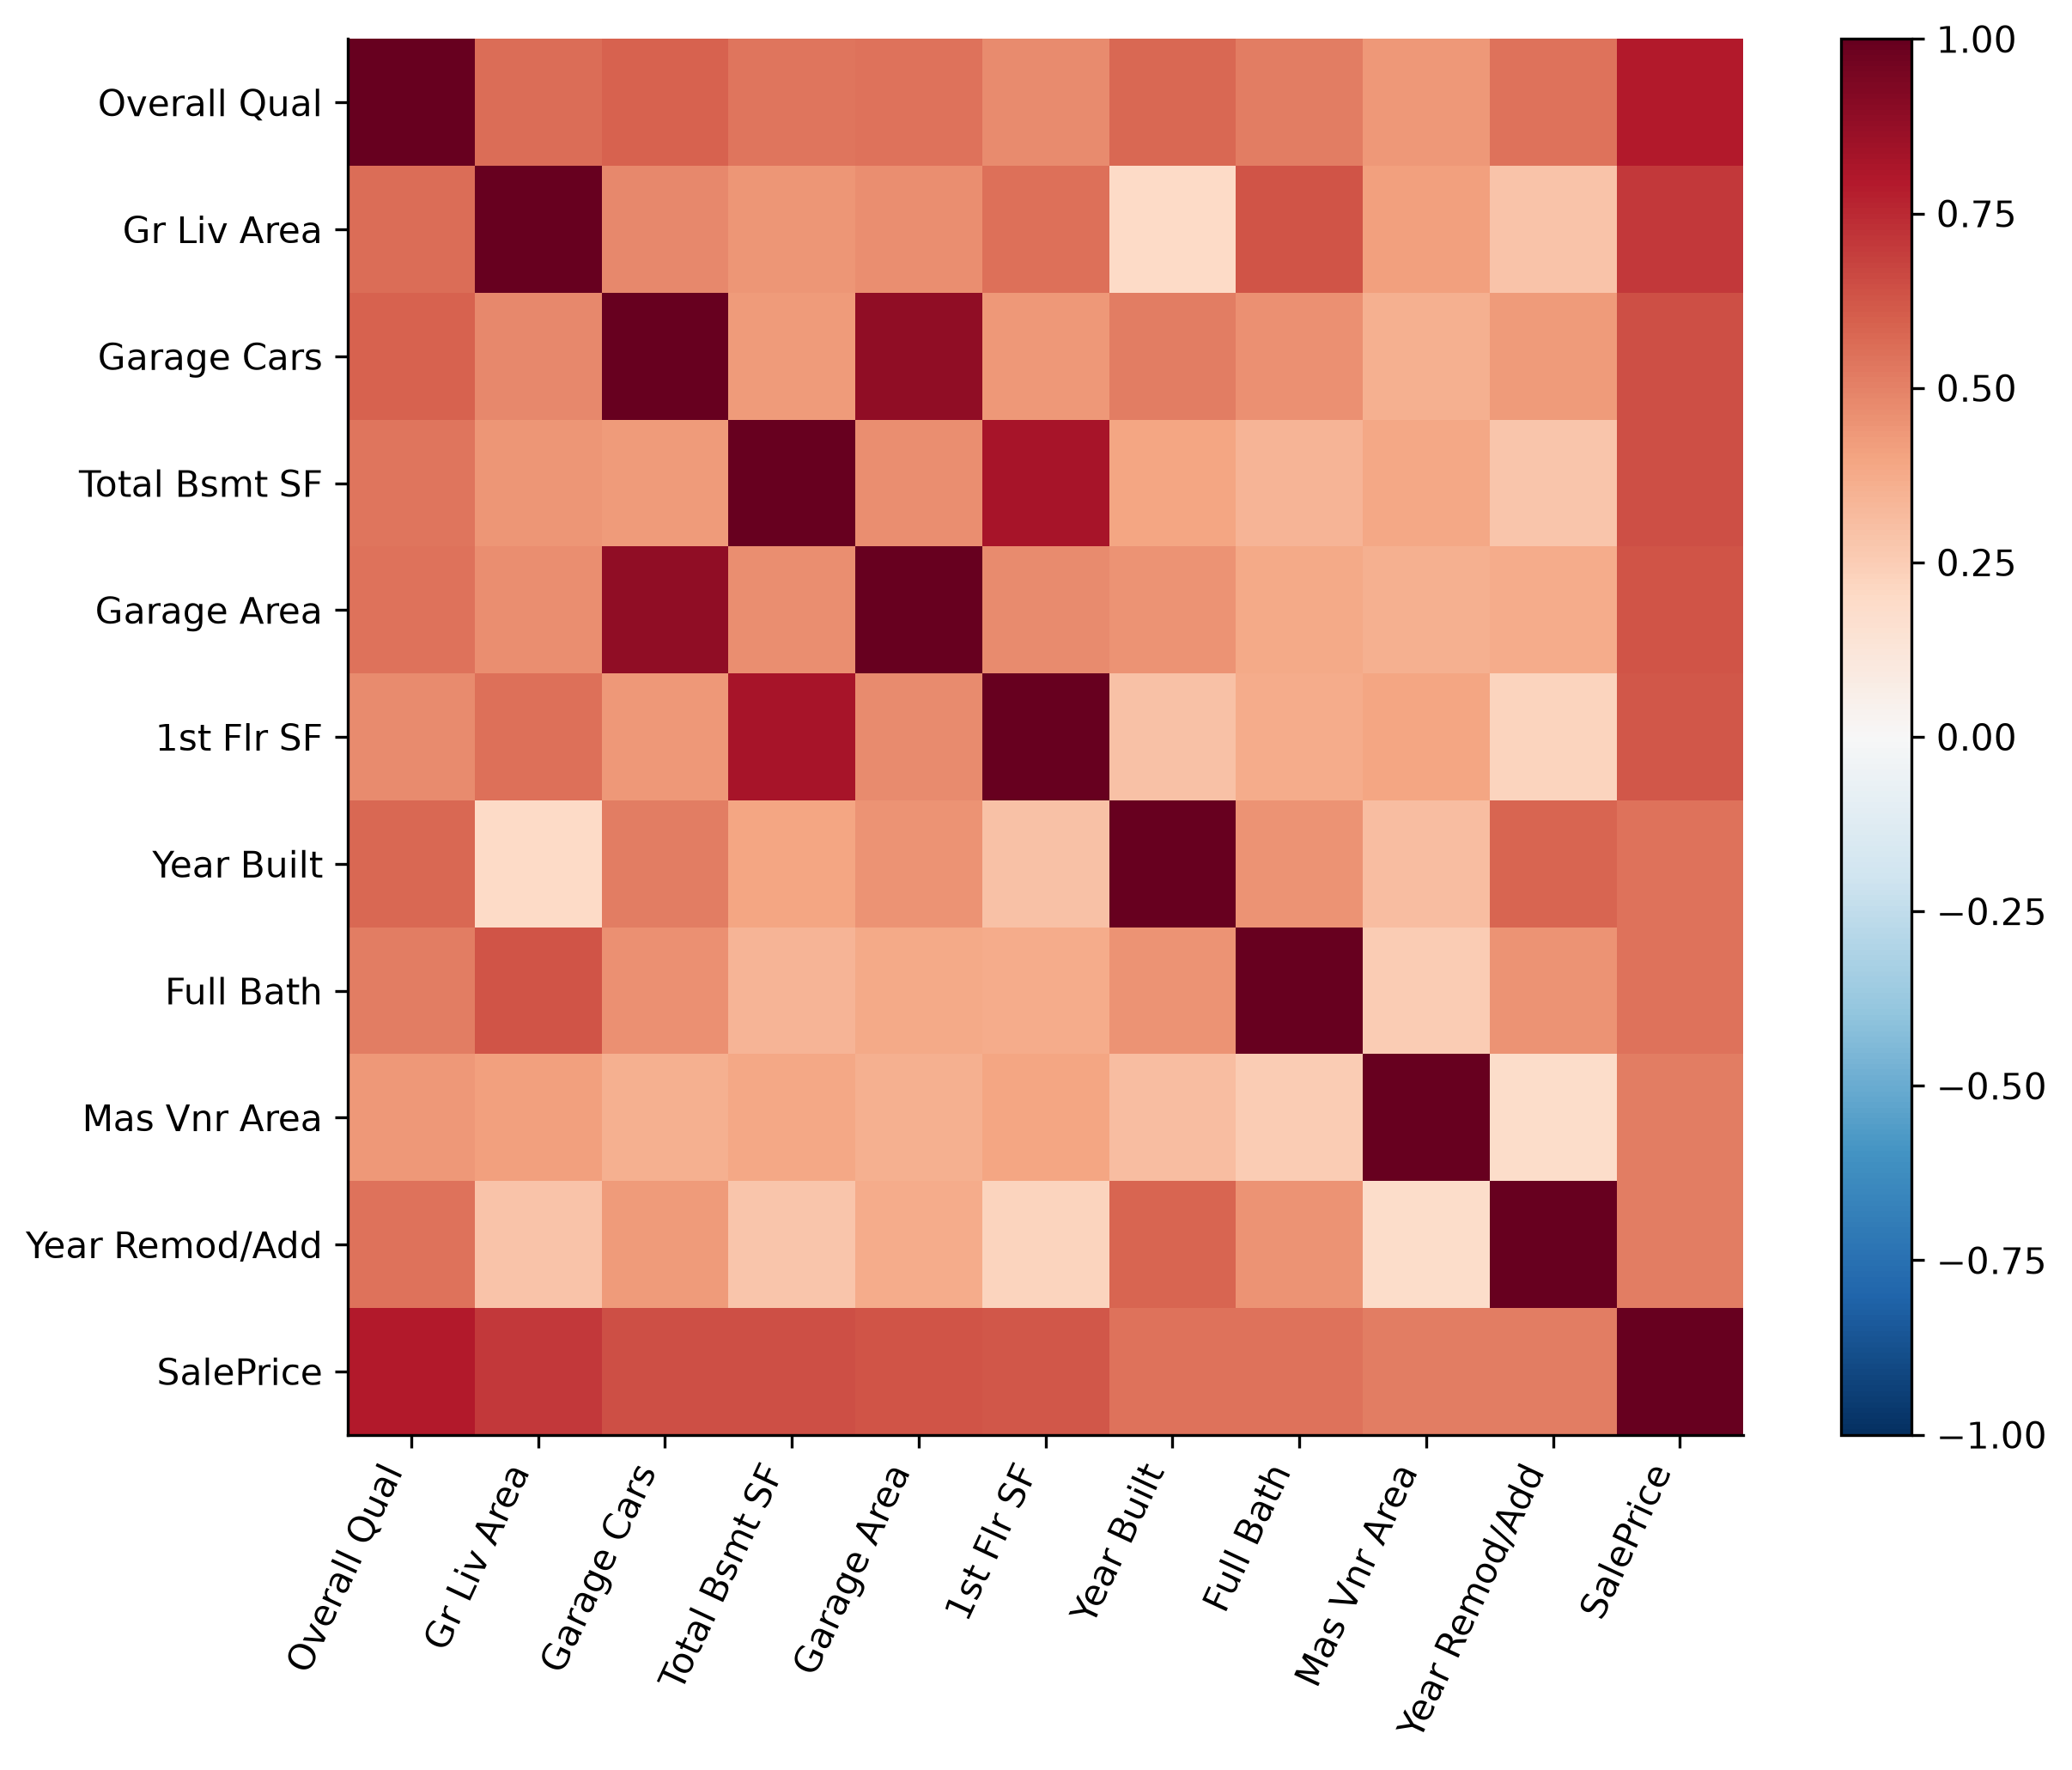

In [14]:
display(Image(filename=str(ROOT / 'lab_01' / 'results' / 'correlations.png')))

### Рисунок 3. Порівняння збіжності трьох оптимізаторів

На рисунку 3 зображено порівняння збіжності трьох оптимізаторів. Криві показують Train MSE/2 наприкінці епохи, а не втрату на окремому батчі. Навіть SGD тому може виглядати значно гладкішим, ніж його покрокова траєкторія.

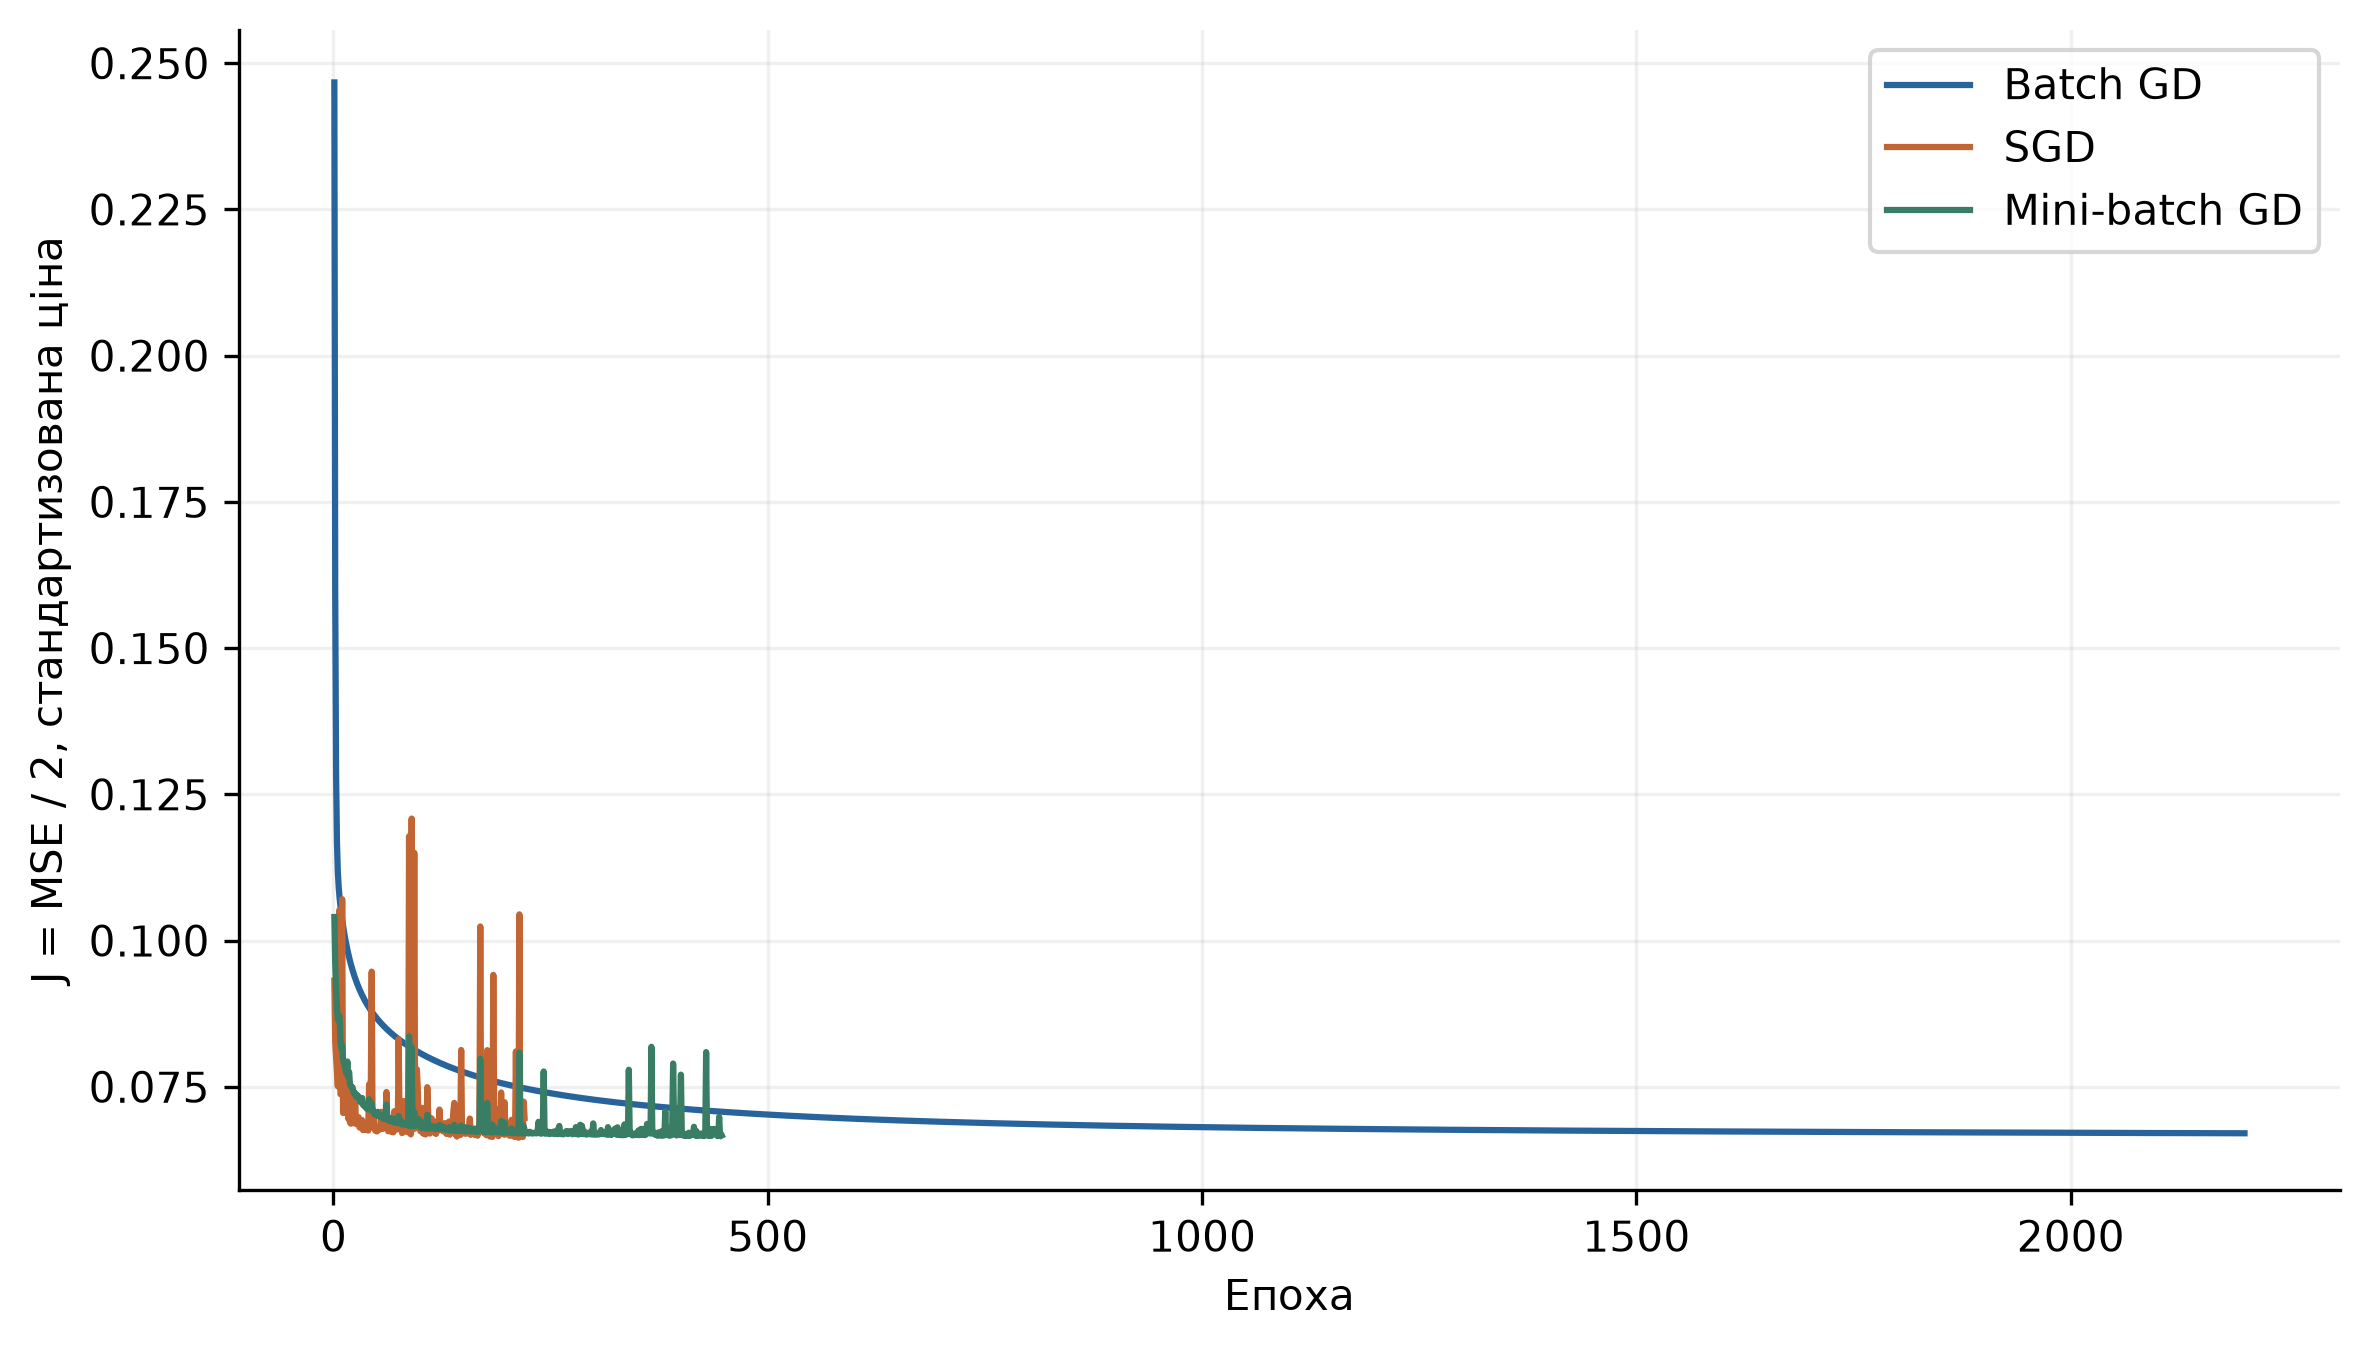

In [15]:
display(Image(filename=str(ROOT / 'lab_01' / 'results' / 'optimization.png')))

### Рисунок 4. Діагностика залишків вибраної лінійної моделі

На рисунку 4 зображено діагностика залишків вибраної лінійної моделі. Залишки розраховано на Train. Q-Q і Scale-Location перевіряють різні властивості: розподіл залишків і залежність їхнього розкиду від прогнозу.

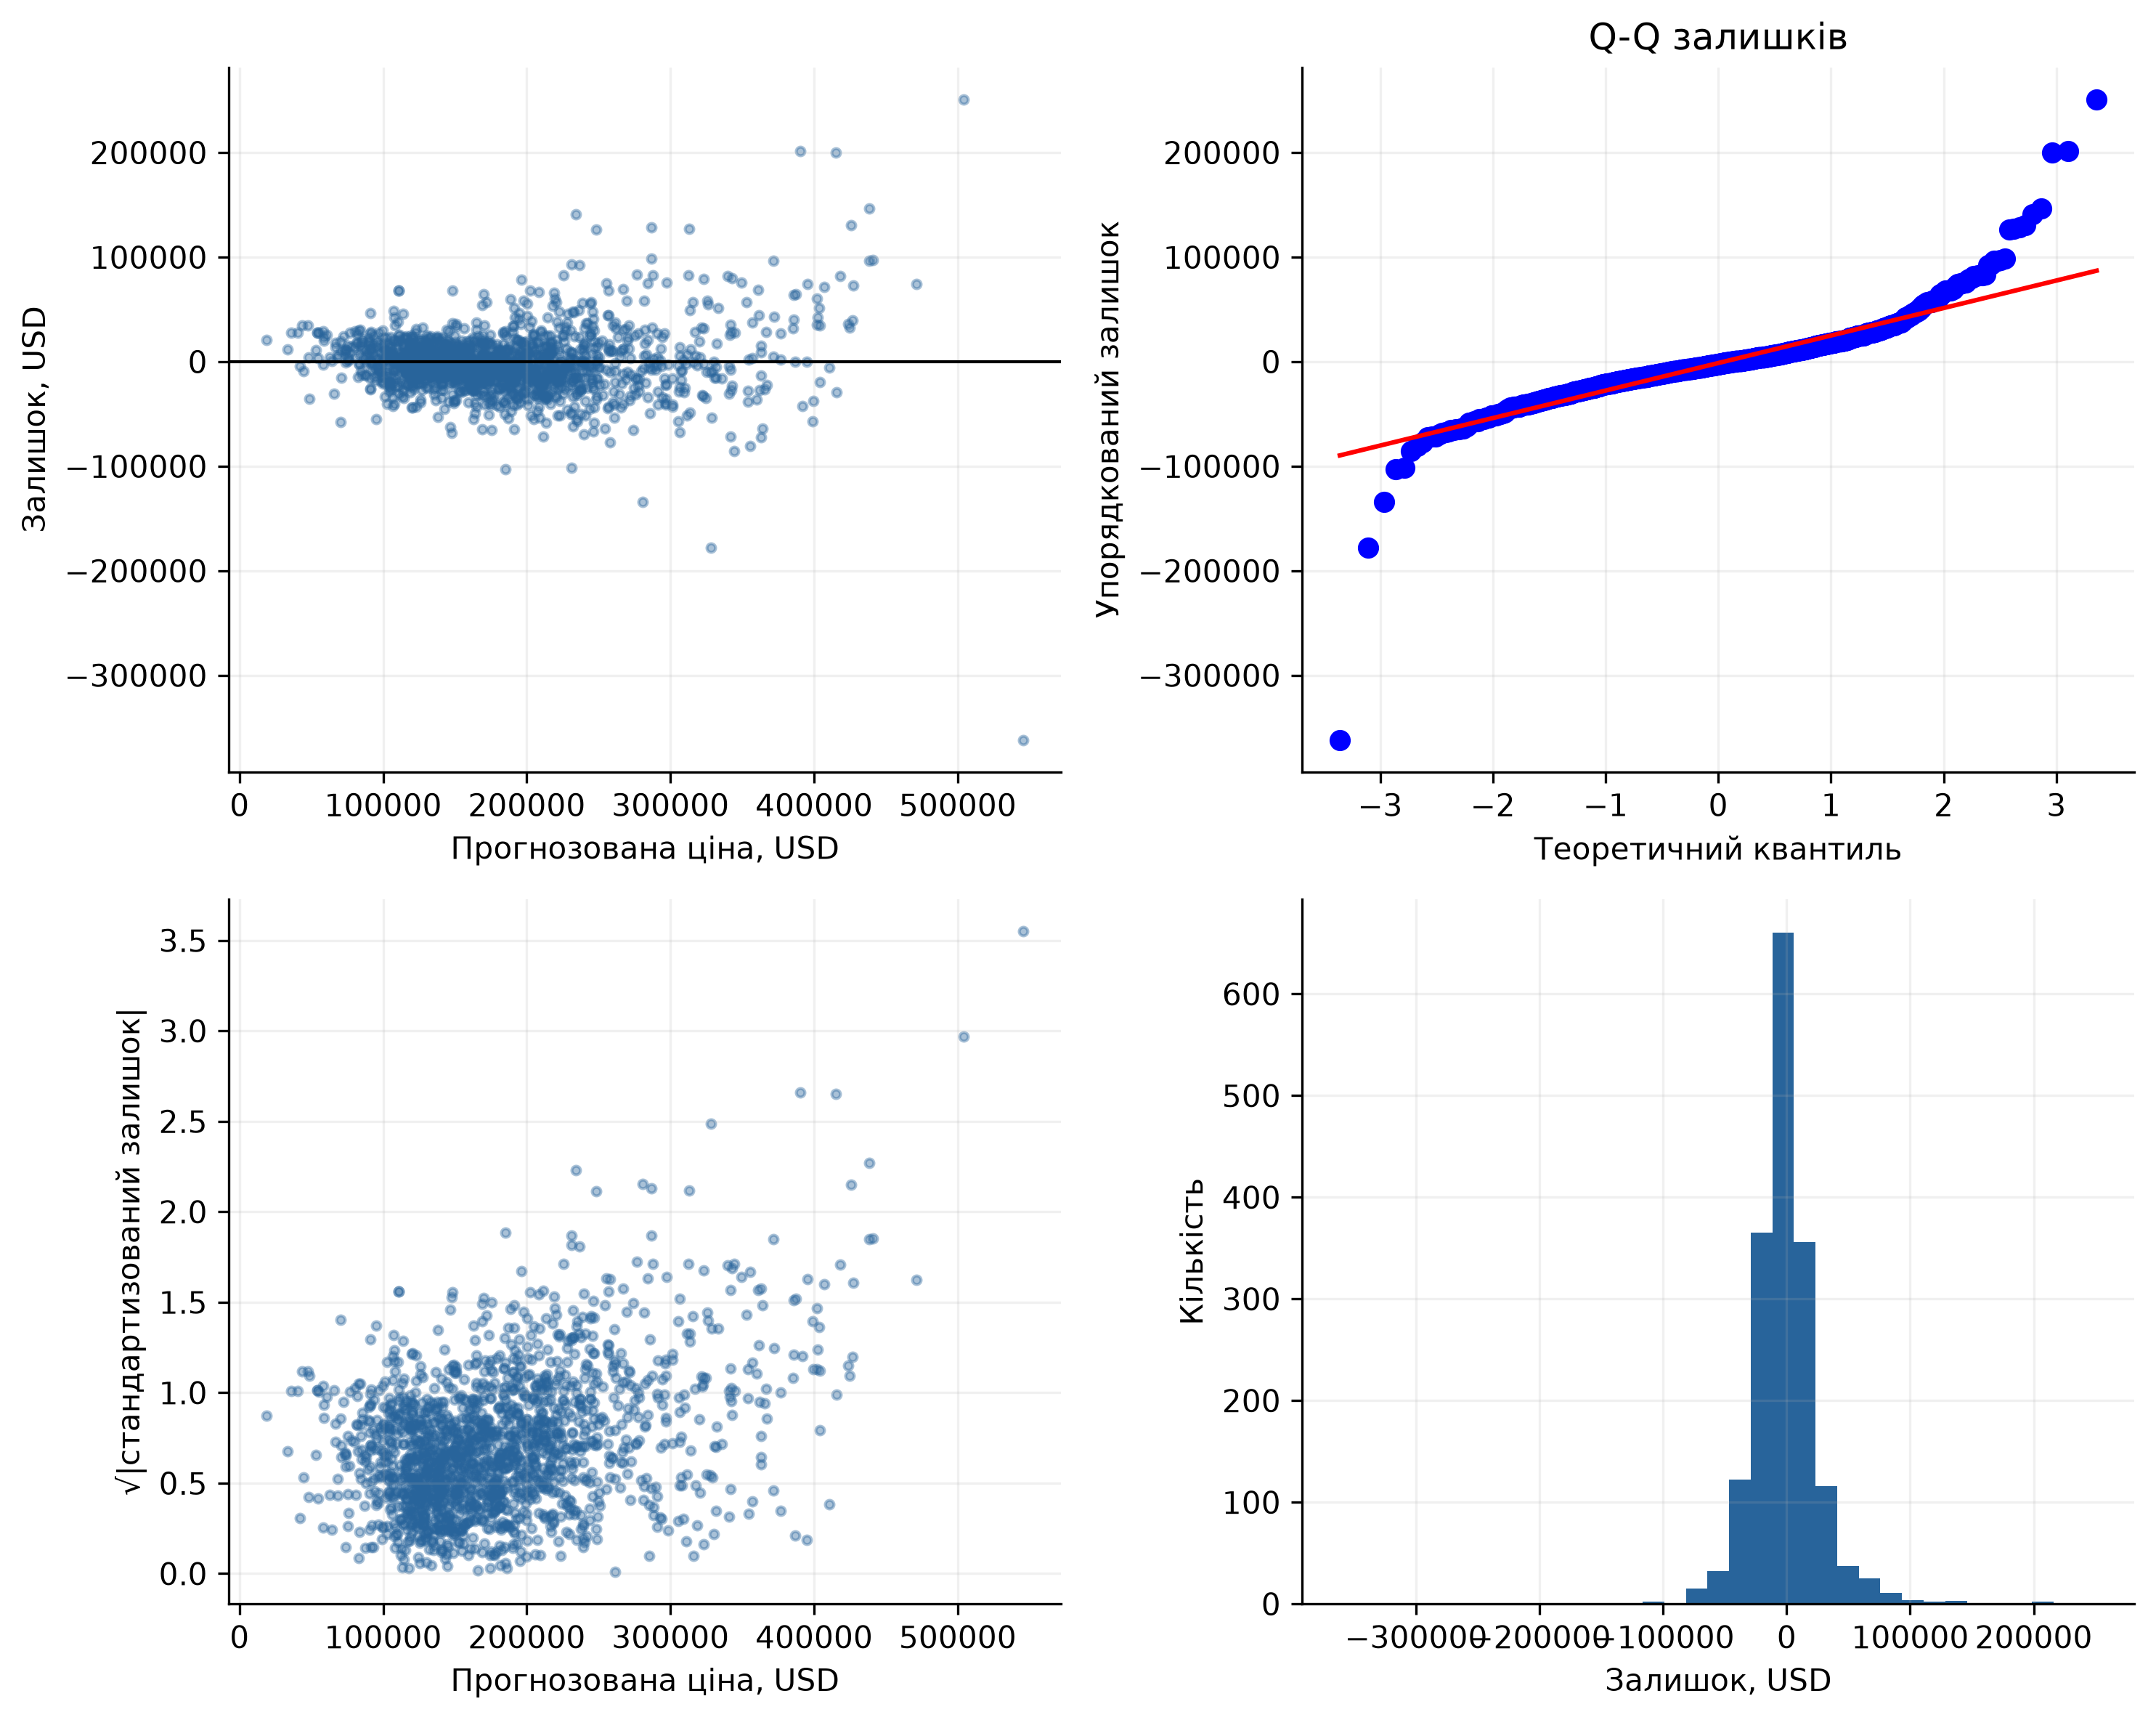

In [16]:
display(Image(filename=str(ROOT / 'lab_01' / 'results' / 'diagnostics.png')))

### Рисунок 5. Вплив Ridge на найбільші коефіцієнти

На рисунку 5 зображено вплив Ridge на найбільші коефіцієнти. Порівнюються ті самі закодовані ознаки та стандартизована ціль. Штраф стискає ваги; його вплив на прогноз оцінюється окремими метриками.

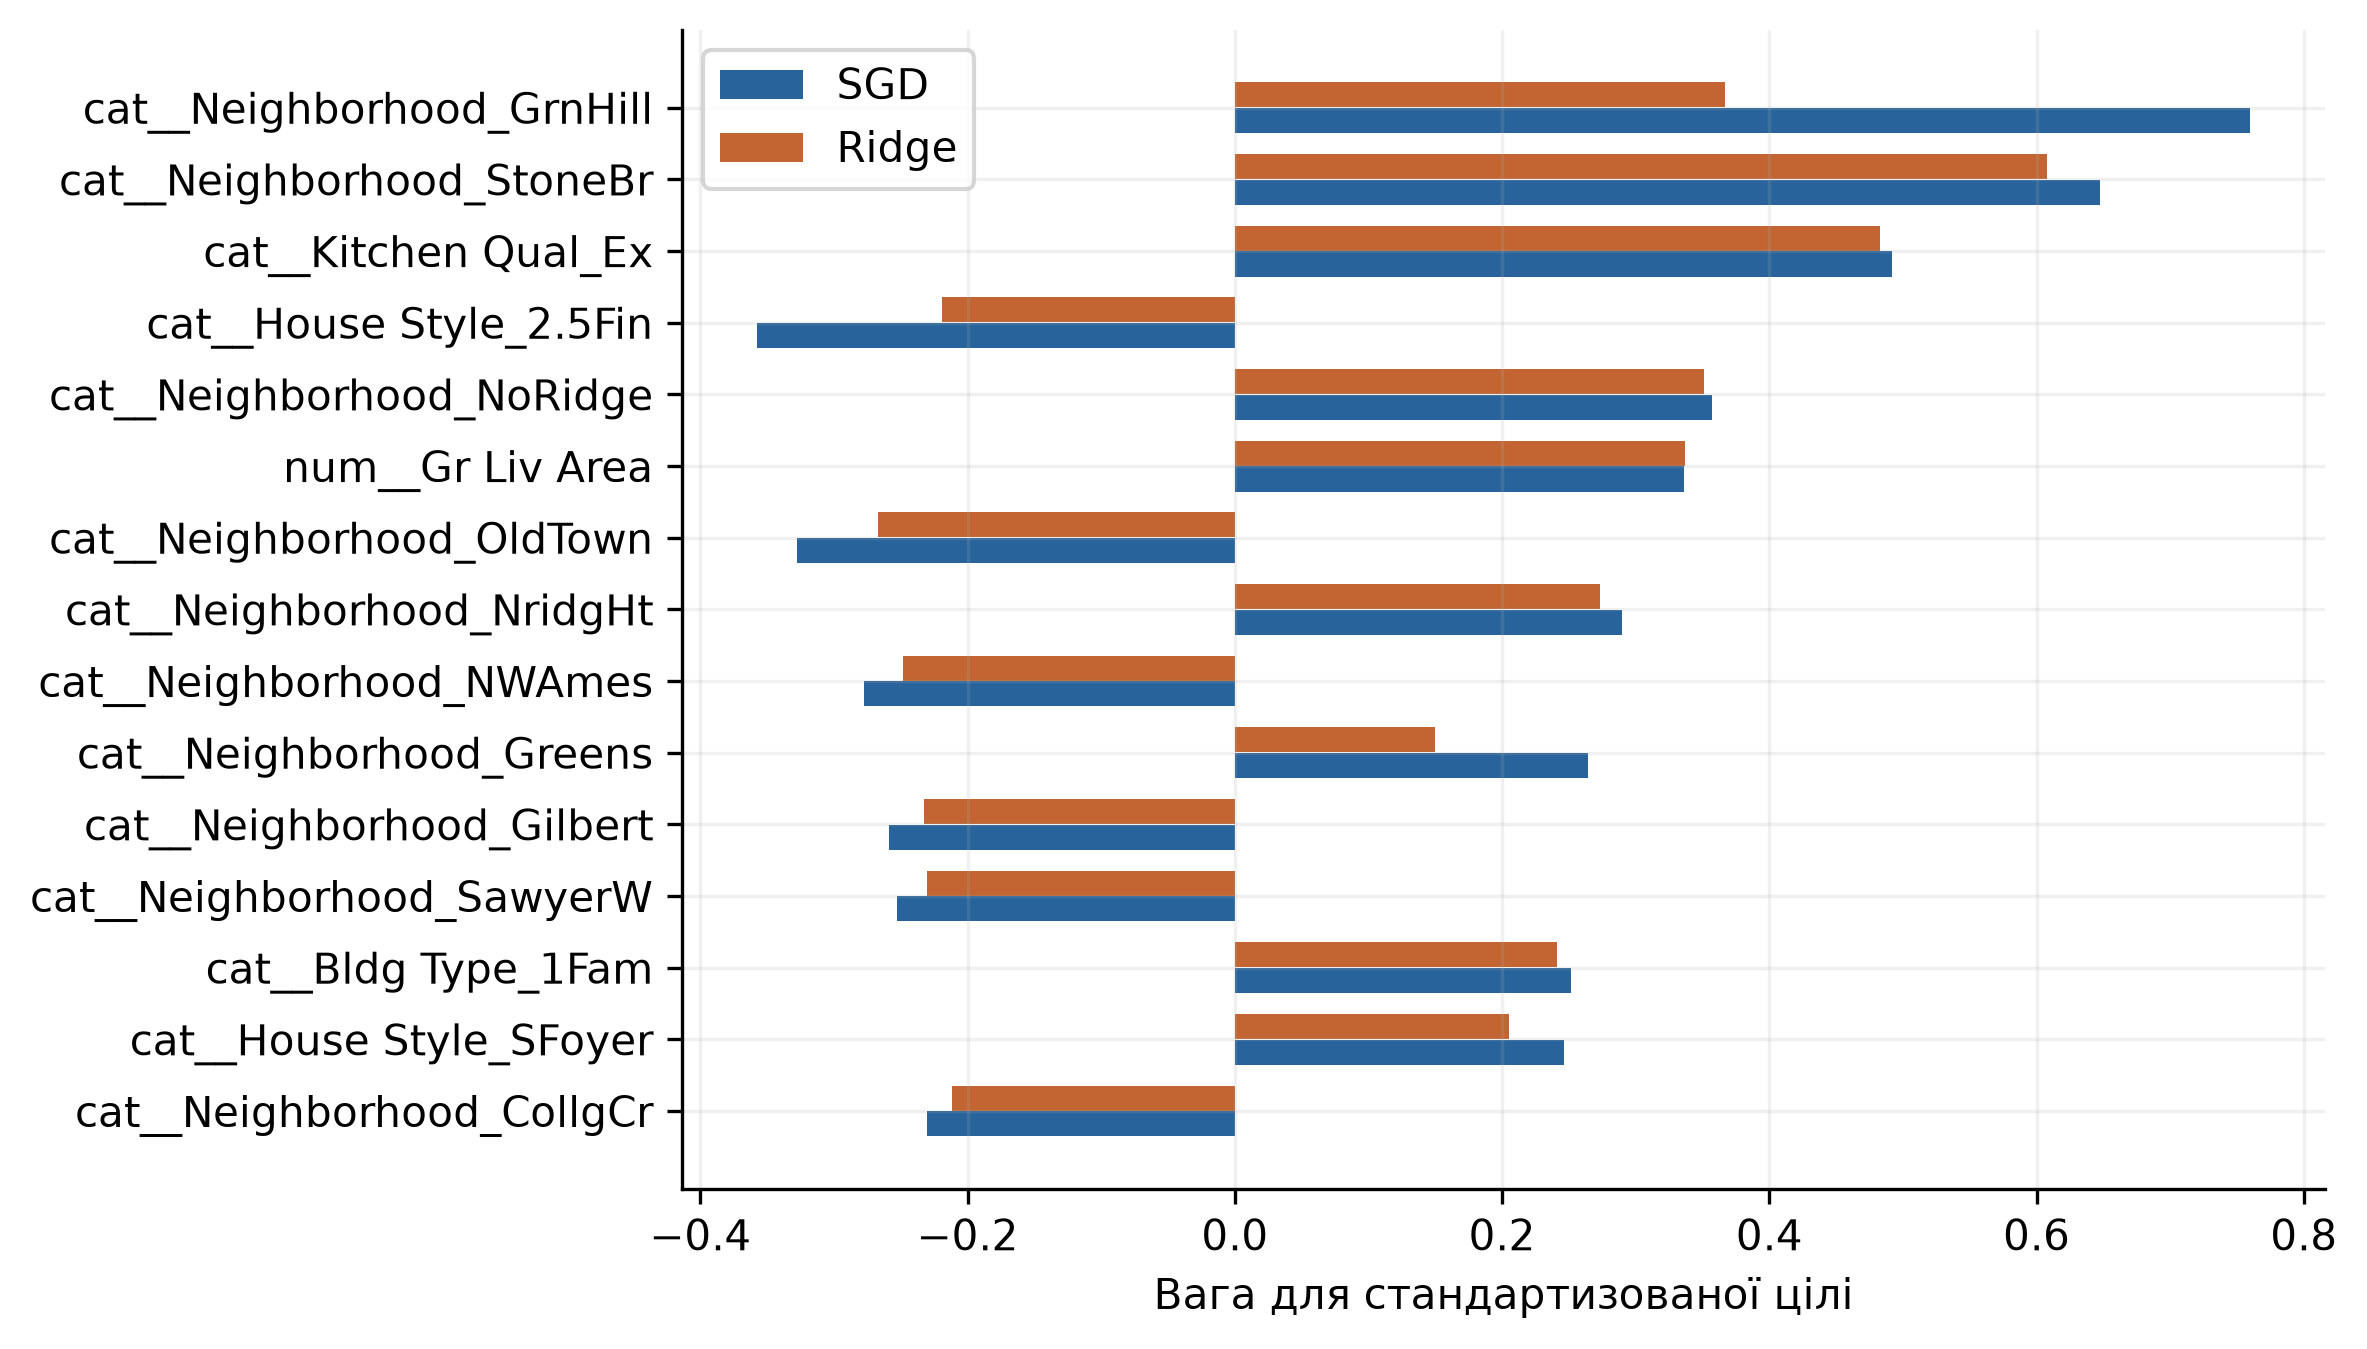

In [17]:
display(Image(filename=str(ROOT / 'lab_01' / 'results' / 'ridge_weights.png')))

## Висновки

In [18]:
for text in conclusions(1, R):
    print(text)

За Validation RMSE вибрав SGD. На Test отримав R²=0,8630, RMSE=30555,01 USD і MAE=19261,07 USD. Результат одержано власним градієнтним навчанням, без Normal Equation.
Найбільший VIF дорівнює 5,63. Перевірки залишків і графіки показують обмеження класичної лінійної інтерпретації, тому якість прогнозу й достовірність окремих коефіцієнтів не ототожнюю. Власні градієнти пройшли чисельну перевірку.


## Джерела

De Cock D. Ames, Iowa: Alternative to the Boston Housing Data. Journal of Statistics Education, 2011. https://jse.amstat.org/v19n3/decock/AmesHousing.txt